In [1]:
# Setup / installation if needed:
# !pip install -q transformers accelerate num2words

# Block 1: Global Config & Reproducibility

In [2]:
from pathlib import Path
import random
from random import sample
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json
from PIL import Image
from io import BytesIO
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    hamming_loss,
    accuracy_score,
    classification_report,
)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# ----- Dataset Paths (Minh-TFR) -----
DATA_PATH = Path("input/datasets/Minh-TFR")

TRAIN_JSONL = DATA_PATH / "train_datas.jsonl"
TEST_JSONL = DATA_PATH / "test_datas.jsonl"

# Checkpoints directory
CHECKPOINT_DIR = Path("/workspace/working/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = CHECKPOINT_DIR / "best_model_multi_label.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")
print(f"Dataset path: {DATA_PATH.resolve()}")
print(f"Best model path: {BEST_MODEL_PATH.resolve()}")

# ----- Reproducibility -----
SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

# ----- Artifact Classes for Multi-Label Classification -----
CLASS_NAMES = [
    "edge_artifacts",
    "unnatural_texture",
    "inconsistent_alignment",
    "inconsistent_font",
    "lack_of_integration",
    "text_incoherence",
]
NUM_CLASSES = len(CLASS_NAMES)

# ----- Hyperparameters -----
TEST_SIZE = 0.1
NUM_WORKERS = 0
BATCH_SIZE = 4

EPOCHS = 20
ENCODER_LR = 5e-4
DECODER_LR = 5e-3
WD = 1e-4
CLS_WEIGHT = 1.0  # Weight for artifact classification loss

TRAIN_MVP = 10323
VAL_MVP = 2000

Device: cuda
Dataset path: /workspace/input/datasets/Minh-TFR
Best model path: /workspace/working/checkpoints/best_model_multi_label.pth


In [3]:
print(f"Checking data files in {DATA_PATH}:")
print(f" - Train jsonl: {TRAIN_JSONL} (exists: {TRAIN_JSONL.exists()})")
print(f" - Test jsonl:  {TEST_JSONL} (exists: {TEST_JSONL.exists()})")

for split in ["train_datas", "test_datas"]:
    imgs_dir = DATA_PATH / split / "imgs"
    masks_dir = DATA_PATH / split / "masks"
    n_imgs = len(list(imgs_dir.glob("*"))) if imgs_dir.exists() else 0
    n_masks = len(list(masks_dir.glob("*"))) if masks_dir.exists() else 0
    print(f" - [{split}] Images: {n_imgs:,} | Masks: {n_masks:,}")

Checking data files in input/datasets/Minh-TFR:
 - Train jsonl: input/datasets/Minh-TFR/train_datas.jsonl (exists: True)
 - Test jsonl:  input/datasets/Minh-TFR/test_datas.jsonl (exists: True)
 - [train_datas] Images: 10,323 | Masks: 10,323
 - [test_datas] Images: 2,000 | Masks: 2,000


# Block 2: Data Discorvering & Data Prepreration

In [4]:
def load_jsonl_records(jsonl_path: Path, data_root: Path = DATA_PATH):
    records = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            item = json.loads(line)

            # Resolve image path
            img_rel = Path(item["images"])
            if img_rel.exists():
                img_path = img_rel
            elif (data_root / img_rel.name).exists():
                img_path = data_root / img_rel.name
            else:
                split_name = "train_datas" if "train" in str(jsonl_path) else "test_datas"
                img_path = data_root / split_name / "imgs" / img_rel.name

            # Resolve mask path (.png in masks/)
            split_dir = img_path.parent.parent
            mask_path = split_dir / "masks" / (img_path.stem + ".png")
            if not mask_path.exists():
                split_name = "train_datas" if "train" in str(jsonl_path) else "test_datas"
                mask_path = data_root / split_name / "masks" / (img_path.stem + ".png")

            # Parse label vector for multi-label classification
            raw_labels = item.get("labels", {})
            label_vec = []
            for c in CLASS_NAMES:
                val = raw_labels.get(c, None)
                if val is None and c == "inconsistent_alignment":
                    val = raw_labels.get("inconsisten_alignment", 0)
                label_vec.append(float(val if val is not None else 0))

            records.append({
                "image_path": str(img_path),
                "mask_path": str(mask_path),
                "labels": label_vec,
                "content": item.get("content", ""),
            })
    return records

all_train_records = load_jsonl_records(TRAIN_JSONL)
test_records = load_jsonl_records(TEST_JSONL)
print(f"Loaded {len(all_train_records):,} train records, {len(test_records):,} test records.")
print("Sample record labels:", {CLASS_NAMES[i]: int(all_train_records[0]["labels"][i]) for i in range(NUM_CLASSES)})

Loaded 10,323 train records, 2,000 test records.
Sample record labels: {'edge_artifacts': 1, 'unnatural_texture': 0, 'inconsistent_alignment': 0, 'inconsistent_font': 0, 'lack_of_integration': 1, 'text_incoherence': 0}


Train samples preview (Mask overlay in red + active classes):


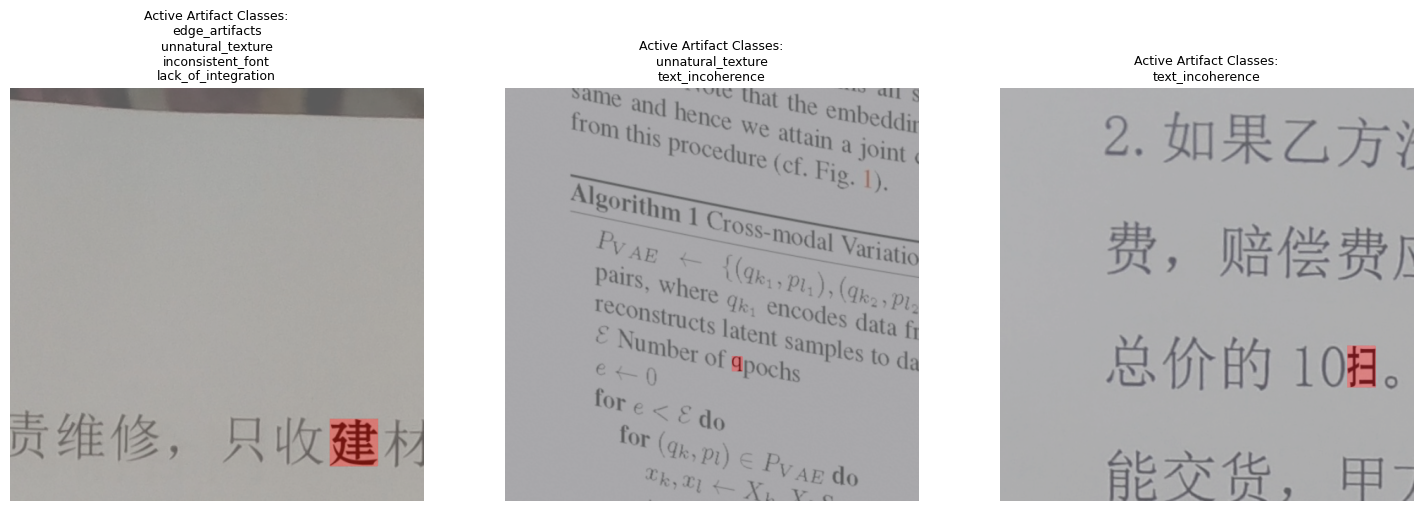

In [5]:
def get_masked_image(record: dict) -> Image.Image:
    image = Image.open(record["image_path"]).convert("RGBA")
    mask = Image.open(record["mask_path"]).convert("L")
    mask_np = np.array(mask)

    tmp = np.zeros((*mask_np.shape, 4), dtype=np.uint8)
    tmp[mask_np > 127] = [255, 0, 0, 255]
    red_mask = Image.fromarray(tmp)

    return Image.blend(im1=image, im2=red_mask, alpha=0.35)

def display_samples(records: list[dict], k=3):
    sampled = sample(records, min(k, len(records)))
    fig, axes = plt.subplots(1, len(sampled), figsize=(len(sampled) * 5, 5))
    if len(sampled) == 1:
        axes = [axes]

    for ax, rec in zip(axes, sampled):
        blended = get_masked_image(rec)
        active_classes = [CLASS_NAMES[i] for i, v in enumerate(rec["labels"]) if v == 1]
        ax.imshow(blended)
        cls_text = "\n".join(active_classes) if active_classes else "None"
        ax.set_title(f"Active Artifact Classes:\n{cls_text}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("Train samples preview (Mask overlay in red + active classes):")
display_samples(all_train_records, k=3)

# Block 3: Validation Strategy & Data Augmentation

In [6]:
train_indices, val_indices = train_test_split(
    np.arange(len(all_train_records)),
    test_size=TEST_SIZE,
    random_state=SEED,
    shuffle=True
)

train_records = [all_train_records[i] for i in train_indices]
val_records = [all_train_records[i] for i in val_indices]

# MVP subset (adjust or comment out to train on full dataset)
train_records = train_records[:TRAIN_MVP]
val_records = val_records[:VAL_MVP]

print(f"Train samples: {len(train_records):,}")
print(f"Validation samples: {len(val_records):,}")
print(f"Test samples: {len(test_records):,}")

print("\nTrain class distribution:")
for j, name in enumerate(CLASS_NAMES):
    cnt = sum(r["labels"][j] for r in train_records)
    print(f"  {name:<25}: {int(cnt):,} ({cnt/len(train_records)*100:.1f}%)")

Train samples: 9,290
Validation samples: 1,033
Test samples: 2,000

Train class distribution:
  edge_artifacts           : 7,073 (76.1%)
  unnatural_texture        : 2,219 (23.9%)
  inconsistent_alignment   : 3,880 (41.8%)
  inconsistent_font        : 2,001 (21.5%)
  lack_of_integration      : 7,892 (85.0%)
  text_incoherence         : 526 (5.7%)


In [7]:
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

mask_transform = transforms.Compose([
    transforms.ToTensor(),
])

# Block 4: Dataset & Data Loader

In [8]:
class MinhTFRDataset(Dataset):
    def __init__(self, records, image_transform=None, mask_transform=None):
        self.records = records
        self.image_transform = image_transform
        self.mask_transform = mask_transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        item = self.records[index]
        image = Image.open(item["image_path"]).convert("RGB")
        mask = Image.open(item["mask_path"]).convert("L")

        image_tensor = self.image_transform(image) if self.image_transform else transforms.ToTensor()(image)
        mask_tensor = (self.mask_transform(mask) > 0.5).float() if self.mask_transform else (transforms.ToTensor()(mask) > 0.5).float()
        labels_tensor = torch.tensor(item["labels"], dtype=torch.float32)

        return image_tensor, mask_tensor, labels_tensor

train_dataset = MinhTFRDataset(train_records, image_transform, mask_transform)
val_dataset = MinhTFRDataset(val_records, image_transform, mask_transform)
test_dataset = MinhTFRDataset(test_records, image_transform, mask_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(device == "cuda"), persistent_workers=(NUM_WORKERS > 0)
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device == "cuda"), persistent_workers=(NUM_WORKERS > 0)
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device == "cuda"), persistent_workers=(NUM_WORKERS > 0)
)

# Block 5: Modeling & Hyperparameter

In [9]:
class DepthwiseSeparableBlock(nn.Module):
    """Lightweight pointwise + depthwise + pointwise convolution block."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1,
                groups=out_channels, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class SCSEModule(nn.Module):
    """Concurrent channel and spatial squeeze-excitation."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 4)

        self.channel_attention = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1),
            nn.Sigmoid(),
        )

        self.spatial_attention = nn.Sequential(
            nn.Conv2d(channels, 1, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        channel_features = x * self.channel_attention(x)
        spatial_features = x * self.spatial_attention(x)
        return channel_features + spatial_features


In [10]:
class BlockDCT(nn.Module):
    """Orthonormal 8x8 block DCT; output: [B, 64, H/8, W/8]."""
    def __init__(self, block_size=8, mean=MEAN, std=STD):
        super().__init__()
        self.block_size = block_size
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

        # Build the orthonormal DCT-II basis.
        n = block_size
        basis = torch.empty(n, n, dtype=torch.float32)
        for u in range(n):
            alpha = (1.0 / n) ** 0.5 if u == 0 else (2.0 / n) ** 0.5
            for pos in range(n):
                basis[u, pos] = alpha * torch.cos(
                    torch.tensor((2 * pos + 1) * u * torch.pi / (2 * n))
                )
        self.register_buffer("basis", basis)

    def forward(self, image):
        # The input image is ImageNet-normalized. Recover RGB in [0, 1].
        # Run fixed DCT operations in FP32 for numerical stability under AMP.
        with torch.autocast(device_type=image.device.type, enabled=False):
            image = image.float() * self.std + self.mean
            image = image.clamp(0.0, 1.0)

            gray = (
                0.299 * image[:, 0:1]
                + 0.587 * image[:, 1:2]
                + 0.114 * image[:, 2:3]
            )

            batch_size, _, height, width = gray.shape
            n = self.block_size
            pad_h = (n - height % n) % n
            pad_w = (n - width % n) % n

            if pad_h or pad_w:
                gray = F.pad(gray, (0, pad_w, 0, pad_h), mode="replicate")

            # Non-overlapping 8x8 blocks.
            patches = F.unfold(gray, kernel_size=n, stride=n)
            grid_h = gray.shape[-2] // n
            grid_w = gray.shape[-1] // n
            patches = patches.transpose(1, 2).reshape(
                batch_size, grid_h * grid_w, n, n
            )

            basis = self.basis.to(device=image.device, dtype=torch.float32)
            coeff = torch.matmul(basis, patches)
            coeff = torch.matmul(coeff, basis.t())

            # [B, number_of_blocks, 8, 8] -> [B, 64, grid_h, grid_w]
            coeff = coeff.reshape(batch_size, grid_h, grid_w, n, n)
            coeff = coeff.permute(0, 3, 4, 1, 2).contiguous()
            coeff = coeff.reshape(batch_size, n * n, grid_h, grid_w)

            # Signed log compression of coefficient range.
            coeff = torch.sign(coeff) * torch.log1p(torch.abs(coeff) * 8.0)

        return coeff


class LightweightFrequencyHead(nn.Module):
    """Small DCT feature encoder; original JPEG QT embedding is omitted."""
    def __init__(self, out_channels=32):
        super().__init__()
        self.block_dct = BlockDCT(block_size=8)

        self.projection = nn.Sequential(
            nn.Conv2d(64, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        self.refine = DepthwiseSeparableBlock(out_channels, out_channels)

    def forward(self, image):
        dct_map = self.block_dct(image)
        features = self.projection(dct_map)
        return self.refine(features)


In [11]:
class LiteMID(nn.Module):
    """
    Lightweight approximation of DTD's Multi-view Iterative Decoder.

    Inputs are ordered from high to low spatial resolution:
      f0: [B, 24,   H/4,  W/4]
      f1: [B, 40,   H/8,  W/8]   (already fused with DCT features)
      f2: [B, 112,  H/16, W/16]
      f3: [B, 1280, H/32, W/32]

    The decoder builds a small nested decoding grid:
      first view:  x00, x11, x22
      second view: x01, x12
      final view:  x02
    """
    def __init__(self, in_channels=(24, 40, 112, 1280), width=48):
        super().__init__()

        self.projections = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(ch, width, kernel_size=1, bias=False),
                nn.BatchNorm2d(width),
                nn.ReLU(inplace=True),
            )
            for ch in in_channels
        ])

        # View 1: adjacent-scale decoding.
        self.x00 = DepthwiseSeparableBlock(width * 2, width)
        self.x11 = DepthwiseSeparableBlock(width * 2, width)
        self.x22 = DepthwiseSeparableBlock(width * 2, width)

        # View 2: aggregate the previous view and encoder skip features.
        self.x01 = DepthwiseSeparableBlock(width * 3, width)
        self.x12 = DepthwiseSeparableBlock(width * 3, width)

        # View 3: final iterative aggregation at H/4.
        self.x02 = DepthwiseSeparableBlock(width * 4, width)

        self.refine = SCSEModule(width)

    @staticmethod
    def upsample_to(x, reference):
        return F.interpolate(
            x,
            size=reference.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

    def forward(self, f0, f1, f2, f3):
        # Project all encoder scales to a compact common channel width.
        p0, p1, p2, p3 = [
            projection(feature)
            for projection, feature in zip(
                self.projections, (f0, f1, f2, f3)
            )
        ]

        # View 1: coarse-to-fine decoding on adjacent scales.
        x00 = self.x00(torch.cat([
            self.upsample_to(p3, p2), p2
        ], dim=1))

        x11 = self.x11(torch.cat([
            self.upsample_to(p2, p1), p1
        ], dim=1))

        x22 = self.x22(torch.cat([
            self.upsample_to(p1, p0), p0
        ], dim=1))

        # View 2: iterative fusion of decoder outputs and encoder features.
        x01 = self.x01(torch.cat([
            self.upsample_to(x00, x11),
            x11,
            p1,
        ], dim=1))

        x12 = self.x12(torch.cat([
            self.upsample_to(x11, x22),
            x22,
            p0,
        ], dim=1))

        # View 3: final multi-view aggregation at 1/4 resolution.
        x02 = self.x02(torch.cat([
            self.upsample_to(x01, x22),
            x12,
            x22,
            p0,
        ], dim=1))

        return self.refine(x02)


class LightweightDTD(nn.Module):
    """
    DTD-inspired lightweight multi-task model:
      - Spatial branch: EfficientNet-B0
      - Frequency branch: block-wise 8x8 DCT
      - Fusion: scSE + 1x1 projection at 1/8 resolution
      - Decoder: LiteMID (nested multi-view iterative decoder)
      - Head 1: Pixel-level tampered text mask logits [B, 1, H, W]
      - Head 2: Multi-label artifact classification logits [B, num_classes] (from shared decoder features)
    """
    def __init__(
        self,
        pretrained=True,
        out_channels=1,
        num_classes=NUM_CLASSES,
        frequency_channels=32,
        decoder_width=48,
    ):
        super().__init__()
        self.num_classes = num_classes

        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        backbone = efficientnet_b0(weights=weights)
        self.encoder = backbone.features

        self.frequency_branch = LightweightFrequencyHead(
            out_channels=frequency_channels
        )

        self.frequency_fusion = nn.Sequential(
            SCSEModule(40 + frequency_channels),
            nn.Conv2d(
                40 + frequency_channels,
                40,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(40),
            nn.ReLU(inplace=True),
        )

        self.decoder = LiteMID(
            in_channels=(24, 40, 112, 1280),
            width=decoder_width,
        )

        # Output 1: Pixel segmentation head
        self.segmentation_head = nn.Conv2d(
            decoder_width,
            out_channels,
            kernel_size=1,
        )

        # Pooling for classification (combining AvgPool and MaxPool to capture global context + peak artifact signals)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        # Output 2: Multi-label artifact classification head using shared multi-scale & frequency-aware decoder features
        self.classification_head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.2),
            nn.Linear(decoder_width * 2, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        input_size = x.shape[-2:]

        # EfficientNet-B0 feature taps:
        # features[2]: 24 channels, stride 4
        # features[3]: 40 channels, stride 8
        # features[5]: 112 channels, stride 16
        # features[8]: 1280 channels, stride 32
        f0 = None
        f1 = None
        f2 = None
        f3 = None

        z = x
        for idx, stage in enumerate(self.encoder):
            z = stage(z)
            if idx == 2:
                f0 = z
            elif idx == 3:
                f1 = z
            elif idx == 5:
                f2 = z
            elif idx == 8:
                f3 = z

        # DCT frequency features are fused at the 1/8 scale.
        freq = self.frequency_branch(x)

        if freq.shape[-2:] != f1.shape[-2:]:
            freq = F.interpolate(
                freq,
                size=f1.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )

        f1 = self.frequency_fusion(
            torch.cat([f1, freq], dim=1)
        )

        # Four-scale iterative decoder (fusing spatial f0..f3 and DCT frequency features)
        decoded = self.decoder(f0, f1, f2, f3)

        # Multi-label artifact classification from shared multi-scale & frequency-aware decoder features
        pooled_avg = self.avg_pool(decoded)
        pooled_max = self.max_pool(decoded)
        pooled_feat = torch.cat([pooled_avg, pooled_max], dim=1)
        class_logits = self.classification_head(pooled_feat)

        # Pixel mask logits: [B, 1, H, W]
        mask_logits = self.segmentation_head(decoded)

        mask_logits = F.interpolate(
            mask_logits,
            size=input_size,
            mode="bilinear",
            align_corners=False,
        )

        return mask_logits, class_logits

    @torch.no_grad()
    def predict(self, x, threshold=0.5, top_k=3):
        """
        Dự đoán đầu ra gồm:
        1. Pixel dự đoán (binary_mask, prob_map)
        2. Top 3 classes có tỉ lệ confident cao nhất
        """
        self.eval()
        mask_logits, class_logits = self.forward(x)
        prob_masks = torch.sigmoid(mask_logits.float())
        pixel_preds = (prob_masks >= threshold).to(torch.uint8)

        class_probs = torch.sigmoid(class_logits.float())
        k = min(top_k, class_probs.shape[-1])
        top_probs, top_indices = torch.topk(class_probs, k=k, dim=-1)

        results = []
        for i in range(x.shape[0]):
            sample_top = [
                (CLASS_NAMES[idx.item()], float(prob.item()))
                for idx, prob in zip(top_indices[i], top_probs[i])
            ]
            all_probs = {
                CLASS_NAMES[j]: float(class_probs[i, j].item())
                for j in range(len(CLASS_NAMES))
            }
            active_classes = [
                (CLASS_NAMES[j], float(class_probs[i, j].item()))
                for j in range(len(CLASS_NAMES))
                if class_probs[i, j] >= threshold
            ]
            results.append({
                "binary_mask": pixel_preds[i, 0].cpu().numpy(),
                "prob_map": prob_masks[i, 0].cpu().numpy(),
                "top3_classes": sample_top,
                "all_class_probs": all_probs,
                "active_classes": active_classes,
            })
        return results[0] if x.shape[0] == 1 else results


model = LightweightDTD(
    pretrained=True,
    out_channels=1,
    num_classes=NUM_CLASSES,
    frequency_channels=32,
    decoder_width=48,
).to(device)

In [12]:
model.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(device)
    mask_output, class_output = model(dummy)

print("Input:", dummy.shape)
print("Pixel mask output:", mask_output.shape)
print("Artifact class output:", class_output.shape)
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

assert mask_output.shape == (2, 1, 224, 224)
assert class_output.shape == (2, NUM_CLASSES)

# Test predict helper for top-3 classes
single_sample_pred = model.predict(dummy[:1])
print("\nSample inference test (.predict):")
print("Pixel mask shape:", single_sample_pred["binary_mask"].shape)
print("Top 3 classes (confidence):", single_sample_pred["top3_classes"])

Input: torch.Size([2, 3, 224, 224])
Pixel mask output: torch.Size([2, 1, 224, 224])
Artifact class output: torch.Size([2, 6])
Total parameters: 4,155,796
Trainable parameters: 4,155,796

Sample inference test (.predict):
Pixel mask shape: (224, 224)
Top 3 classes (confidence): [('inconsistent_alignment', 0.5808864831924438), ('text_incoherence', 0.5645852088928223), ('edge_artifacts', 0.5285449624061584)]


In [13]:
class MultiTaskTamperLoss(nn.Module):
    def __init__(self, dice_weight=1.0, cls_weight=1.0, smooth=1.0):
        super().__init__()
        self.bce_seg = nn.BCEWithLogitsLoss()
        self.bce_cls = nn.BCEWithLogitsLoss()
        self.dice_weight = dice_weight
        self.cls_weight = cls_weight
        self.smooth = smooth

    def forward(self, mask_logits, class_logits, mask_targets, class_targets):
        mask_logits = mask_logits.float()
        bce_seg = self.bce_seg(mask_logits, mask_targets)
        probs = torch.sigmoid(mask_logits)
        inter = (probs * mask_targets).sum()
        dice = (2.0 * inter + self.smooth) / (probs.sum() + mask_targets.sum() + self.smooth)
        seg_loss = bce_seg + self.dice_weight * (1.0 - dice)

        class_logits = class_logits.float()
        cls_loss = self.bce_cls(class_logits, class_targets)

        total_loss = seg_loss + self.cls_weight * cls_loss
        return total_loss, seg_loss, cls_loss


criterion = MultiTaskTamperLoss(dice_weight=1.0, cls_weight=CLS_WEIGHT)

encoder_params = list(model.encoder.parameters())
other_params = [
    param
    for name, param in model.named_parameters()
    if not name.startswith("encoder.")
]
optimizer = torch.optim.AdamW([
    {"params": encoder_params, "lr": ENCODER_LR},
    {"params": other_params, "lr": DECODER_LR},
], weight_decay=WD)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

# Block 6: Training & Validation Loop

In [14]:
def calculate_batch_dice(logits, masks, threshold=0.5, smooth=1e-6):
    predictions = (torch.sigmoid(logits) >= threshold).float()
    targets = (masks >= 0.5).float()

    predictions = predictions.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (predictions * targets).sum(dim=1)
    pred_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    dice = (2.0 * intersection + smooth) / (
        pred_sum + target_sum + smooth
    )

    return dice.sum().item(), dice.numel()


def calculate_multilabel_metrics(all_probs: np.ndarray, all_targets: np.ndarray, threshold: float = 0.5):
    """
    Tính toán các chỉ số đánh giá chuẩn và toàn diện cho bài toán Multi-Label Classification:
      1. Macro F1: F1 trung bình giữa các class (trọng số bình đẳng, phản ánh tốt khi dữ liệu imbalanced)
      2. Micro F1: F1 tổng hợp trên toàn bộ các nhãn
      3. mAP (Mean Average Precision): Đo diện tích dưới đường cong PR (ranking chất lượng của từng class)
      4. Exact Match (Subset Accuracy): Tỷ lệ mẫu dự đoán đúng hoàn toàn 100% tất cả các nhãn
      5. Hamming Loss: Tỷ lệ nhãn bị dự đoán sai (càng nhỏ càng tốt, 0 là hoàn hảo)
      6. Classification Report: Báo cáo chi tiết Precision, Recall, F1 cho từng artifact class
    """
    preds = (all_probs >= threshold).astype(int)
    targets = all_targets.astype(int)

    macro_f1 = float(f1_score(targets, preds, average="macro", zero_division=0))
    micro_f1 = float(f1_score(targets, preds, average="micro", zero_division=0))
    macro_precision = float(precision_score(targets, preds, average="macro", zero_division=0))
    macro_recall = float(recall_score(targets, preds, average="macro", zero_division=0))

    try:
        map_score = float(average_precision_score(targets, all_probs, average="macro"))
    except Exception:
        map_score = 0.0

    exact_match = float(accuracy_score(targets, preds))
    h_loss = float(hamming_loss(targets, preds))

    report = classification_report(
        targets, preds, target_names=CLASS_NAMES, zero_division=0
    )

    return {
        "macro_f1": macro_f1,
        "micro_f1": micro_f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "mAP": map_score,
        "exact_match": exact_match,
        "hamming_loss": h_loss,
        "report": report,
    }


def calculate_topk_hit(class_logits, class_targets, k=3):
    """Kiểm tra xem ít nhất 1 class dương tính thực tế có nằm trong top-k dự đoán không (dùng tham khảo phụ)."""
    probs = torch.sigmoid(class_logits)
    _, top_indices = torch.topk(probs, k=min(k, probs.shape[-1]), dim=-1)
    hits = 0
    total = 0
    for i in range(class_targets.shape[0]):
        gt_pos = (class_targets[i] == 1).nonzero(as_tuple=True)[0]
        if len(gt_pos) == 0:
            continue
        total += 1
        predicted_set = set(top_indices[i].tolist())
        if any(idx.item() in predicted_set for idx in gt_pos):
            hits += 1
    return hits, max(total, 1)


In [15]:
@torch.no_grad()
def validate_one_epoch(model, loader, criterion, threshold=0.5):
    model.eval()

    running_total_loss = 0.0
    running_seg_loss = 0.0
    running_cls_loss = 0.0
    total_dice = 0.0
    total_images = 0

    all_cls_probs = []
    all_cls_targets = []

    progress_bar = tqdm(loader, desc="Validation")

    for images, masks, labels in progress_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            mask_logits, cls_logits = model(images)
            total_loss, seg_loss, cls_loss = criterion(mask_logits, cls_logits, masks, labels)

        batch_size = images.size(0)
        batch_dice_sum, num_images = calculate_batch_dice(mask_logits, masks, threshold=threshold)

        running_total_loss += total_loss.item() * batch_size
        running_seg_loss += seg_loss.item() * batch_size
        running_cls_loss += cls_loss.item() * batch_size
        total_dice += batch_dice_sum
        total_images += num_images

        # Accumulate probabilities and labels for robust multi-label metrics
        cls_probs = torch.sigmoid(cls_logits).float().cpu().numpy()
        all_cls_probs.append(cls_probs)
        all_cls_targets.append(labels.cpu().numpy())

        progress_bar.set_postfix(
            loss=f"{total_loss.item():.4f}",
            val_dice=f"{total_dice / total_images:.4f}",
        )

    all_cls_probs = np.concatenate(all_cls_probs, axis=0)
    all_cls_targets = np.concatenate(all_cls_targets, axis=0)

    cls_metrics = calculate_multilabel_metrics(all_cls_probs, all_cls_targets, threshold=threshold)

    avg_loss = running_total_loss / len(loader.dataset)
    avg_macro_dice = total_dice / total_images

    return avg_loss, avg_macro_dice, cls_metrics


In [16]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    running_loss = 0.0

    progress_bar = tqdm(loader, desc="Train")

    for images, masks, labels in progress_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            mask_logits, cls_logits = model(images)
            total_loss, seg_loss, cls_loss = criterion(mask_logits, cls_logits, masks, labels)

        scaler.scale(total_loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        running_loss += total_loss.item() * batch_size

        progress_bar.set_postfix(
            loss=f"{total_loss.item():.4f}",
            seg=f"{seg_loss.item():.4f}",
            cls=f"{cls_loss.item():.4f}"
        )

    return running_loss / len(loader.dataset)

In [17]:
best_val_dice = -1.0
best_val_macro_f1 = -1.0

for epoch in range(EPOCHS):
    print(f"\n--- Epoch {epoch+1}/{EPOCHS} ---")

    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
    print(f"train_loss: {train_loss:.4f}")

    val_loss, val_dice, cls_metrics = validate_one_epoch(model, val_loader, criterion)
    print(
        f"val_loss: {val_loss:.4f} | val_dice: {val_dice:.4f} | "
        f"val_macro_f1: {cls_metrics['macro_f1']:.4f} | "
        f"val_micro_f1: {cls_metrics['micro_f1']:.4f} | "
        f"val_mAP: {cls_metrics['mAP']:.4f}"
    )

    scheduler.step()

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        best_val_macro_f1 = cls_metrics["macro_f1"]
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_dice": best_val_dice,
            "val_macro_f1": cls_metrics["macro_f1"],
            "val_micro_f1": cls_metrics["micro_f1"],
            "val_mAP": cls_metrics["mAP"],
            "val_exact_match": cls_metrics["exact_match"],
        }, BEST_MODEL_PATH)
        print(f"Saved new best model (Val dice: {best_val_dice:.4f} | Val Macro-F1: {cls_metrics['macro_f1']:.4f})")

print(f"\nTraining completed. Best Val Dice: {best_val_dice:.4f}")



--- Epoch 1/20 ---


Train: 100%|██████████| 2323/2323 [01:57<00:00, 19.69it/s, cls=0.3787, loss=0.8092, seg=0.4305]


train_loss: 1.1465


Validation: 100%|██████████| 259/259 [00:37<00:00,  6.82it/s, loss=1.6974, val_dice=0.1882]


val_loss: 1.1437 | val_dice: 0.1882 | val_macro_f1: 0.5059 | val_micro_f1: 0.7636 | val_mAP: 0.6456
Saved new best model (Val dice: 0.1882 | Val Macro-F1: 0.5059)

--- Epoch 2/20 ---


Train: 100%|██████████| 2323/2323 [01:52<00:00, 20.67it/s, cls=0.3104, loss=0.6616, seg=0.3513]


... (71 outputs left out)

Train: 100%|██████████| 2323/2323 [01:49<00:00, 21.20it/s, cls=0.1931, loss=0.2680, seg=0.0749]


train_loss: 0.5340


Validation: 100%|██████████| 259/259 [00:36<00:00,  7.15it/s, loss=0.5407, val_dice=0.6036]

val_loss: 0.6090 | val_dice: 0.6036 | val_macro_f1: 0.6418 | val_micro_f1: 0.8080 | val_mAP: 0.6772

Training completed. Best Val Dice: 0.6065


# Block 7: Inference, Evaluation & Visualization

In [18]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

model.eval();
print(f"Loaded checkpoint from {BEST_MODEL_PATH}")
if "best_val_dice" in checkpoint:
    print(f"Checkpoint Best Val Dice: {checkpoint['best_val_dice']:.4f}")
if "val_macro_f1" in checkpoint:
    print(f"Checkpoint Best Val Macro-F1: {checkpoint['val_macro_f1']:.4f}")
if "val_mAP" in checkpoint:
    print(f"Checkpoint Best Val mAP: {checkpoint['val_mAP']:.4f}")


Loaded checkpoint from /workspace/working/checkpoints/best_model_multi_label.pth
Checkpoint Best Val Dice: 0.6065
Checkpoint Best Val Macro-F1: 0.6464
Checkpoint Best Val mAP: 0.6778


In [19]:
@torch.no_grad()
def evaluate(model, loader, device, threshold=0.5, dataset_name="Test"):
    model.eval()

    # Global pixel counts for Micro metrics
    tp = 0
    fp = 0
    fn = 0
    tn = 0

    # Per-image Dice aggregation for Macro Dice
    total_dice = 0.0
    total_images = 0

    all_cls_probs = []
    all_cls_targets = []
    total_top3_hits = 0
    total_cls_samples = 0

    progress_bar = tqdm(loader, desc=f"Evaluating {dataset_name}")

    for images, masks, labels in progress_bar:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device,
            dtype=torch.float16,
            enabled=(device == "cuda")
        ):
            mask_logits, cls_logits = model(images)

        predictions = (torch.sigmoid(mask_logits) >= threshold).to(torch.uint8)
        targets = (masks >= 0.5).to(torch.uint8)

        # Micro pixel metrics
        tp += ((predictions == 1) & (targets == 1)).sum().item()
        fp += ((predictions == 1) & (targets == 0)).sum().item()
        fn += ((predictions == 0) & (targets == 1)).sum().item()
        tn += ((predictions == 0) & (targets == 0)).sum().item()

        # Macro Dice
        batch_dice_sum, num_images = calculate_batch_dice(
            mask_logits, masks, threshold=threshold
        )
        total_dice += batch_dice_sum
        total_images += num_images

        # Multi-label class probabilities & targets
        cls_probs = torch.sigmoid(cls_logits).float().cpu().numpy()
        all_cls_probs.append(cls_probs)
        all_cls_targets.append(labels.cpu().numpy())

        # Top-3 class hit rate (tham khảo phụ)
        hits, count = calculate_topk_hit(cls_logits, labels, k=3)
        total_top3_hits += hits
        total_cls_samples += count

        progress_bar.set_postfix(
            macro_dice=f"{batch_dice_sum / num_images:.4f}",
        )

    # Pixel segmentation metrics
    eps = 1e-7
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)
    macro_dice = total_dice / total_images

    # Multi-label artifact classification metrics
    all_cls_probs = np.concatenate(all_cls_probs, axis=0)
    all_cls_targets = np.concatenate(all_cls_targets, axis=0)
    cls_metrics = calculate_multilabel_metrics(all_cls_probs, all_cls_targets, threshold=threshold)
    top3_hit_rate = total_top3_hits / total_cls_samples

    results = {
        "Dataset": dataset_name,
        # Segmentation metrics
        "Precision_Micro": precision,
        "Recall_Micro": recall,
        "Macro_Dice": macro_dice,
        "IoU_Micro": iou,
        "Pixel_Accuracy": accuracy,
        # Multi-label classification metrics
        "Macro_F1": cls_metrics["macro_f1"],
        "Micro_F1": cls_metrics["micro_f1"],
        "Macro_Precision": cls_metrics["macro_precision"],
        "Macro_Recall": cls_metrics["macro_recall"],
        "mAP": cls_metrics["mAP"],
        "Exact_Match": cls_metrics["exact_match"],
        "Hamming_Loss": cls_metrics["hamming_loss"],
        "Top3_Class_Hit_Rate": top3_hit_rate,
        "Report": cls_metrics["report"],
    }

    print(
        f"\n[{dataset_name} Segmentation Results]\n"
        f"  Precision (Micro):    {precision:.4f}\n"
        f"  Recall (Micro):       {recall:.4f}\n"
        f"  Macro Dice:           {macro_dice:.4f}\n"
        f"  IoU (Micro):          {iou:.4f}\n"
        f"  Pixel Accuracy:       {accuracy:.4f}\n"
        f"\n[{dataset_name} Multi-Label Classification Results]\n"
        f"  Macro F1:             {cls_metrics['macro_f1']:.4f}\n"
        f"  Micro F1:             {cls_metrics['micro_f1']:.4f}\n"
        f"  Macro Precision:      {cls_metrics['macro_precision']:.4f}\n"
        f"  Macro Recall:         {cls_metrics['macro_recall']:.4f}\n"
        f"  mAP (PR-AUC):         {cls_metrics['mAP']:.4f}\n"
        f"  Exact Match (Subset): {cls_metrics['exact_match']:.4f}\n"
        f"  Hamming Loss:         {cls_metrics['hamming_loss']:.4f}\n"
        f"  Top-3 Hit Rate (Aux): {top3_hit_rate:.4f}\n"
        f"\n[Classification Report by Class]\n"
        f"{cls_metrics['report']}\n"
    )

    return results


In [20]:
test_results = evaluate(model, test_loader, device, threshold=0.5, dataset_name="Minh-TFR TestSet")

Evaluating Minh-TFR TestSet: 100%|██████████| 500/500 [01:11<00:00,  6.97it/s, macro_dice=0.9449]



[Minh-TFR TestSet Segmentation Results]
  Precision (Micro):    0.9009
  Recall (Micro):       0.7793
  Macro Dice:           0.6218
  IoU (Micro):          0.7178
  Pixel Accuracy:       0.9979

[Minh-TFR TestSet Multi-Label Classification Results]
  Macro F1:             0.5860
  Micro F1:             0.7749
  Macro Precision:      0.5589
  Macro Recall:         0.6550
  mAP (PR-AUC):         0.6102
  Exact Match (Subset): 0.2705
  Hamming Loss:         0.1942
  Top-3 Hit Rate (Aux): 0.9845

[Classification Report by Class]
                        precision    recall  f1-score   support

        edge_artifacts       0.79      0.88      0.83      1499
     unnatural_texture       0.70      0.96      0.81       490
inconsistent_alignment       0.40      0.15      0.21       813
     inconsistent_font       0.61      0.95      0.74       437
   lack_of_integration       0.85      1.00      0.92      1693
      text_incoherence       0.00      0.00      0.00       116

             micr

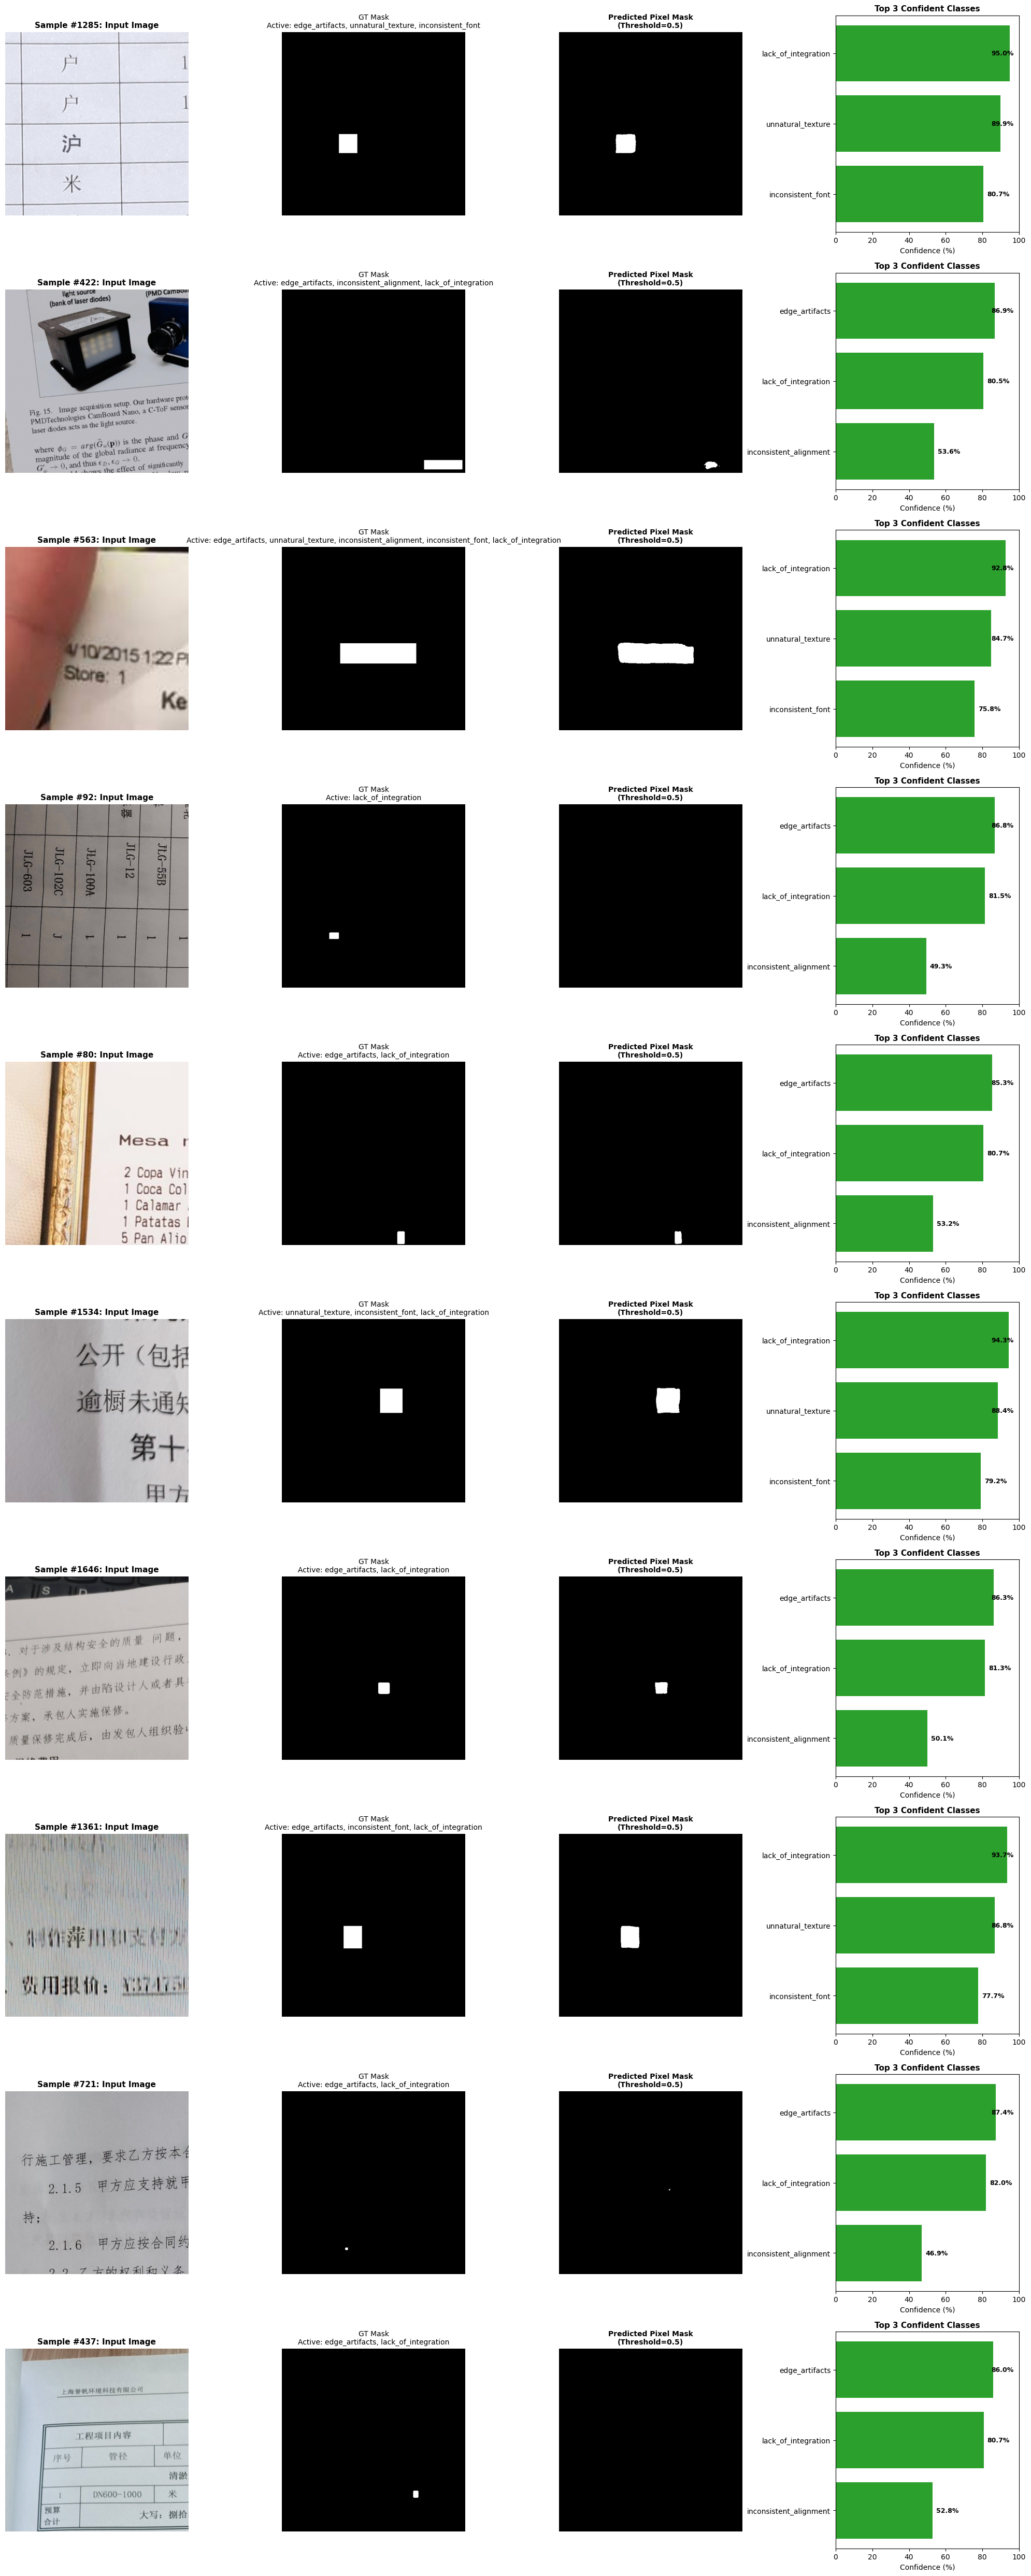

In [21]:
@torch.no_grad()
def visualize_predictions(model, dataset, device, num_samples=5, threshold=0.5):
    """
    Hiển thị trực quan:
    1. Ảnh gốc
    2. Ground Truth Mask & Ground Truth Classes
    3. Pixel dự đoán (Predicted Mask)
    4. Top 3 Classes có tỉ lệ confident cao nhất
    """
    model.eval()

    if len(dataset) == 0:
        print("Dataset is empty.")
        return

    vis_rng = random.Random(SEED + 2)
    selected_indices = vis_rng.sample(
        range(len(dataset)),
        k=min(num_samples, len(dataset))
    )

    fig, axes = plt.subplots(
        len(selected_indices), 4,
        figsize=(20, 5 * len(selected_indices)),
        squeeze=False
    )

    for row, idx in enumerate(selected_indices):
        image_tensor, mask_tensor, labels_tensor = dataset[idx]

        # Dự đoán pixel và top 3 classes
        pred_result = model.predict(image_tensor.unsqueeze(0).to(device), threshold=threshold, top_k=3)
        pred_mask = pred_result["binary_mask"]
        top3_classes = pred_result["top3_classes"]

        # Undo ImageNet normalization for display
        mean = torch.tensor(MEAN).view(3, 1, 1)
        std = torch.tensor(STD).view(3, 1, 1)
        image_for_display = (image_tensor.cpu() * std + mean).clamp(0, 1)
        image_np = image_for_display.permute(1, 2, 0).numpy()
        mask_np = mask_tensor.squeeze().cpu().numpy()

        # 1. Ảnh gốc
        axes[row, 0].imshow(image_np)
        axes[row, 0].set_title(f"Sample #{idx}: Input Image", fontsize=11, fontweight="bold")
        axes[row, 0].axis("off")

        # 2. Ground truth mask + active GT classes
        gt_classes = [CLASS_NAMES[i] for i, v in enumerate(labels_tensor) if v == 1]
        gt_title = "GT Mask\nActive: " + (", ".join(gt_classes) if gt_classes else "None")
        axes[row, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[row, 1].set_title(gt_title, fontsize=10)
        axes[row, 1].axis("off")

        # 3. Pixel dự đoán (Predicted Mask)
        axes[row, 2].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
        axes[row, 2].set_title("Predicted Pixel Mask\n(Threshold=0.5)", fontsize=10, fontweight="bold")
        axes[row, 2].axis("off")

        # 4. Top 3 Classes có tỉ lệ confident cao nhất
        class_labels = [item[0] for item in top3_classes]
        conf_scores = [item[1] * 100 for item in top3_classes]

        bars = axes[row, 3].barh(class_labels[::-1], conf_scores[::-1], color="#2ca02c")
        axes[row, 3].set_xlim(0, 100)
        axes[row, 3].set_xlabel("Confidence (%)", fontsize=10)
        axes[row, 3].set_title("Top 3 Confident Classes", fontsize=11, fontweight="bold")
        for bar in bars:
            width = bar.get_width()
            axes[row, 3].text(
                min(width + 2, 85), bar.get_y() + bar.get_height() / 2,
                f"{width:.1f}%",
                va="center", ha="left", fontsize=9, fontweight="bold"
            )

    plt.tight_layout()
    plt.show()


# Chạy trực quan hóa dự đoán
visualize_predictions(model, test_dataset, device, num_samples=10)

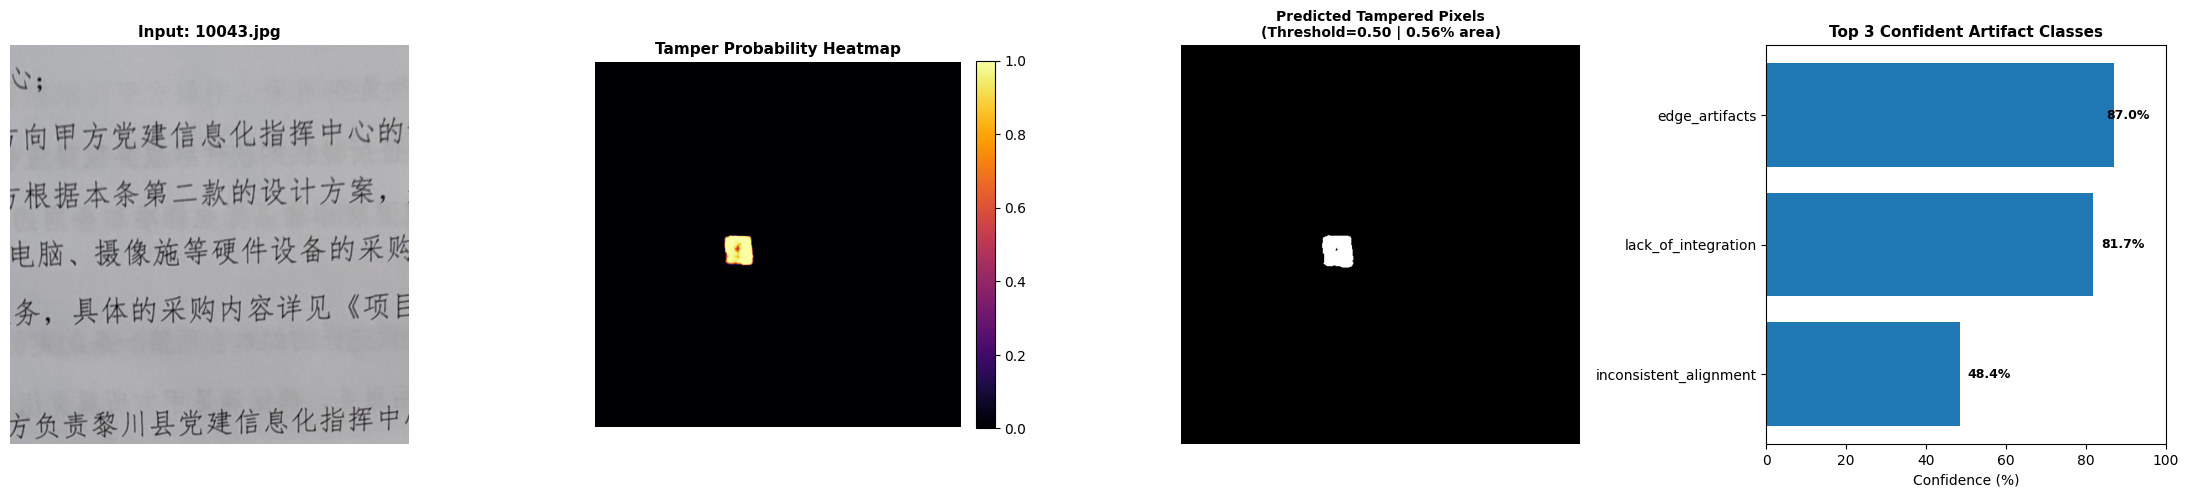

KẾT QUẢ DỰ ĐOÁN: 10043.jpg
- Số pixel bị nghi vấn chỉnh sửa: 1,921 (0.56% diện tích)
- Top 3 Classes có tỉ lệ confident cao nhất:
    1. edge_artifacts           : 86.96%
    2. lack_of_integration      : 81.69%
    3. inconsistent_alignment   : 48.38%


In [22]:
@torch.no_grad()
def predict_and_visualize_single_image(
    model,
    image_input,
    device=device,
    threshold=0.5,
    top_k=3,
):
    """
    Dự đoán và trực quan hóa cho một ảnh tài liệu bất kỳ:
    - pixel dự đoán (binary mask & probability map)
    - top 3 classes có tỉ lệ confident cao nhất
    """
    model.eval()

    if isinstance(image_input, (str, Path)):
        image = Image.open(image_input).convert("RGB")
        img_title = Path(image_input).name
    elif isinstance(image_input, Image.Image):
        image = image_input.convert("RGB")
        img_title = "Custom PIL Image"
    else:
        raise ValueError("image_input phải là đường dẫn ảnh hoặc PIL.Image")

    # Chuẩn bị tensor đầu vào
    img_tensor = image_transform(image).unsqueeze(0).to(device)

    # Dự đoán
    result = model.predict(img_tensor, threshold=threshold, top_k=top_k)
    binary_mask = result["binary_mask"]
    prob_map = result["prob_map"]
    top3_classes = result["top3_classes"]
    all_class_probs = result["all_class_probs"]

    # Hiển thị trực quan
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))

    # 1. Ảnh gốc
    axes[0].imshow(image)
    axes[0].set_title(f"Input: {img_title}", fontsize=11, fontweight="bold")
    axes[0].axis("off")

    # 2. Probability Heatmap
    im1 = axes[1].imshow(prob_map, cmap="inferno", vmin=0, vmax=1)
    axes[1].set_title("Tamper Probability Heatmap", fontsize=11, fontweight="bold")
    axes[1].axis("off")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    # 3. Binary Tampered Pixel Mask
    axes[2].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
    tamper_pixel_count = int(binary_mask.sum())
    tamper_pct = (tamper_pixel_count / binary_mask.size) * 100
    axes[2].set_title(
        f"Predicted Tampered Pixels\n(Threshold={threshold:.2f} | {tamper_pct:.2f}% area)",
        fontsize=10,
        fontweight="bold"
    )
    axes[2].axis("off")

    # 4. Top 3 Confident Classes
    class_labels = [item[0] for item in top3_classes]
    conf_scores = [item[1] * 100 for item in top3_classes]

    bars = axes[3].barh(class_labels[::-1], conf_scores[::-1], color="#1f77b4")
    axes[3].set_xlim(0, 100)
    axes[3].set_xlabel("Confidence (%)", fontsize=10)
    axes[3].set_title(f"Top {top_k} Confident Artifact Classes", fontsize=11, fontweight="bold")
    for bar in bars:
        width = bar.get_width()
        axes[3].text(
            min(width + 2, 85), bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va="center", ha="left", fontsize=9, fontweight="bold"
        )

    plt.tight_layout()
    plt.show()

    # In kết quả dạng text
    print("=" * 60)
    print(f"KẾT QUẢ DỰ ĐOÁN: {img_title}")
    print("=" * 60)
    print(f"- Số pixel bị nghi vấn chỉnh sửa: {tamper_pixel_count:,} ({tamper_pct:.2f}% diện tích)")
    print(f"- Top {top_k} Classes có tỉ lệ confident cao nhất:")
    for rank, (c_name, c_conf) in enumerate(top3_classes, start=1):
        print(f"    {rank}. {c_name:<25}: {c_conf * 100:.2f}%")
    print("=" * 60)

    return result

# Chạy thử nghiệm dự đoán trên 1 ảnh mẫu từ test set
if len(test_records) > 0:
    sample_test_img_path = test_records[9]["image_path"]
    sample_pred_result = predict_and_visualize_single_image(
        model,
        sample_test_img_path,
        device=device,
        threshold=0.5,
        top_k=3
    )